# Imports

In [ ]:
import os
import time
import random
import yaml
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score

%matplotlib inline

# Pathing

In [ ]:
WS_PATH = os.path.dirname(os.getcwd())
SRC_PATH = os.path.join(WS_PATH, 'src')
DATA_PATH = os.path.join(SRC_PATH, 'dataset_yolo')
TEST_IMAGE_DIR = os.path.join(DATA_PATH, 'images', 'test')
TRAIN_RESULT_PATH = os.path.join(SRC_PATH, 'training_results')
RUNS_PATH = os.path.join(TRAIN_RESULT_PATH, 'runs')
YAML_PATH = os.path.join(DATA_PATH, 'data.yaml')

# Functions

## Plot Functions

### Plot Training Result Curve

In [ ]:
def plot_training_curves(results_csv_path: str, model_name: str):
    
    # Read training result as dataframe
    df = pd.read_csv(results_csv_path)

    epochs = df['epoch']

    # Loss curve line plot
    plt.figure()
    plt.plot(epochs, df['train/box_loss'], label='train_box', color='blue')
    plt.plot(epochs, df['train/cls_loss'], label='train_cls', color='green')
    plt.plot(epochs, df['train/dfl_loss'], label='train_dfl', color='orange')

    plt.plot(epochs, df['val/box_loss'], linestyle='--', label='val_box', color='blue')
    plt.plot(epochs, df['val/cls_loss'], linestyle='--', label='val_cls', color='green')
    plt.plot(epochs, df['val/dfl_loss'], linestyle='--', label='val_dfl', color='orange')

    plt.title(f'{model_name} Loss Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Evaluation metrics curve line pLot
    plt.figure()
    plt.plot(epochs, df['metrics/precision(B)'], label='precision')
    plt.plot(epochs, df['metrics/recall(B)'], label='recall')
    plt.plot(epochs, df['metrics/mAP50(B)'], label='mAP50')
    plt.plot(epochs, df['metrics/mAP50-95(B)'], label='mAP50-95')

    plt.title(f'{model_name} Metrics Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.show()

### Plot Training Results by Comparison

In [ ]:
def plot_training_comparison(results_csv_paths: list[str], model_names: list[str]):
    color = sns.color_palette('tab10')  # Custom color

    # Loss curves line plot
    plt.figure()

    for i in range(len(model_names)):

        # Read training result as dataframe
        df = pd.read_csv(results_csv_paths[i])
        
        epochs = df["epoch"]
        name = model_names[i]

        df['train/total_loss'] = (
            df['train/box_loss'] + df['train/cls_loss'] + df['train/dfl_loss']
        )
        df['val/total_loss'] = (
            df['val/box_loss'] + df['val/cls_loss'] + df['val/dfl_loss']
        )

        plt.plot(epochs, df['train/total_loss'], label=f'{name}/train_loss', c=color[i], alpha=0.9)
        plt.plot(epochs, df['val/total_loss'], label=f'{name}/val_loss', linestyle="--", c=color[i], alpha=0.6)

    plt.title(f"Model Loss Curves")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    # mAP50-95 curves line pLot
    plt.figure()

    for i in range(len(model_names)):

        # Read training result as dataframe
        df = pd.read_csv(results_csv_paths[i])
        
        epochs = df["epoch"]
        name = model_names[i]

        plt.plot(epochs, df["metrics/mAP50-95(B)"], label=f'{name}/mAP50-95', c=color[i], alpha=0.9)

    plt.title(f"Model mAP50-95 Curves")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

### Plot Confusion Matrix on Test Set

In [ ]:
def plot_confusion_matrix(confusion_matrix: np.matrix, model_name: str):
    index = confusion_matrix.to_df()['Predicted']
    columns = confusion_matrix.to_df().columns[1:]
    df_confusion = pd.DataFrame(confusion_matrix.matrix, index=index, columns=columns)
    df_confusion = df_confusion.astype(int)

    plt.figure(figsize=(20, 15))
    sns.heatmap(df_confusion, annot=True, cmap='Blues')
    plt.title(f'Confusion Matrix of {model_name} Model', fontsize=18)
    plt.xlabel('Actual', fontsize=18)
    plt.ylabel('Predicted', fontsize=18)
    plt.show()

: 

### Plot Random Predictions

In [ ]:
def show_random_predictions(model_path: str, image_dir: str, n=3):
    model = YOLO(model_path)
    images = random.sample(os.listdir(image_dir), n)

    for img in images:
        img_path = os.path.join(image_dir, img)

        results = model.predict(img_path)[0]

        plotted = results.plot()

        plt.figure()
        plt.imshow(cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB))
        plt.title(img)
        plt.axis("off")
        plt.show()

## Evaluation Computation Functions

### Get The Evaluation Metrics on Test Set

In [ ]:
def evaluate_model(model_path: str, model_name: str, yaml_path: str):

    # Predict the test set and evaluate the predictions
    model = YOLO(model_path)
    metrics = model.val(
        data=yaml_path, split='test', exist_ok=True,
        project=RUNS_PATH, name=model_name
    )

    # Get model's evaluation metrics
    precision = np.mean(metrics.box.p)
    recall = np.mean(metrics.box.r)
    map50 = metrics.box.map50
    map5095 = metrics.box.map
    f1 = np.mean(metrics.box.f1)
    latency = metrics.speed['inference']
    confusion_matrix = metrics.confusion_matrix
    
    return {
        'precision': precision,
        'recall': recall,
        'mAP50': map50,
        'mAP50-95': map5095,
        'f1-score': f1,
        'latency': latency,
        'confusion': confusion_matrix
    }

# Execution

## Plot Training Results

### Plot Each Model Curves

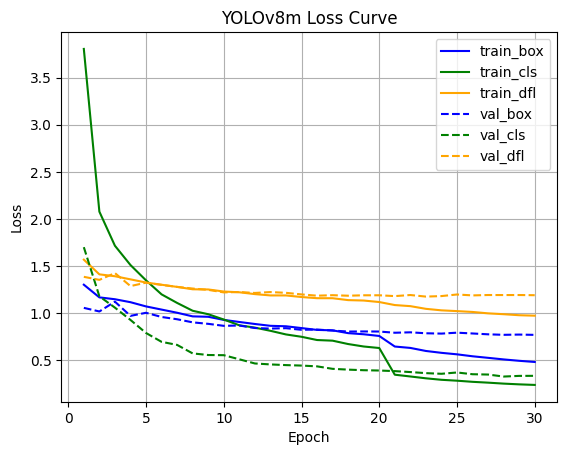

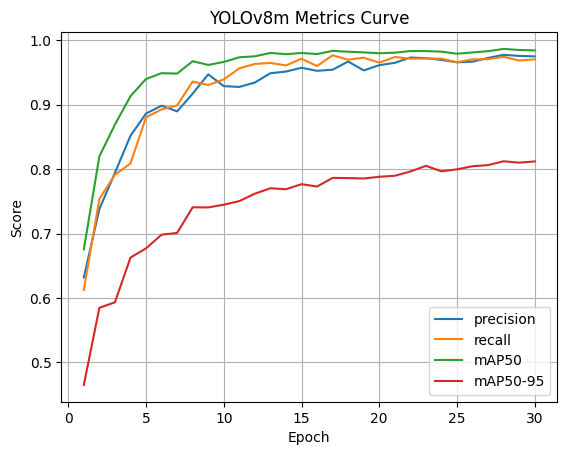

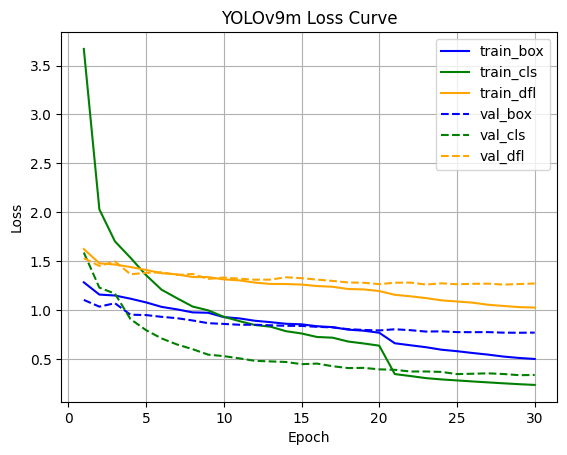

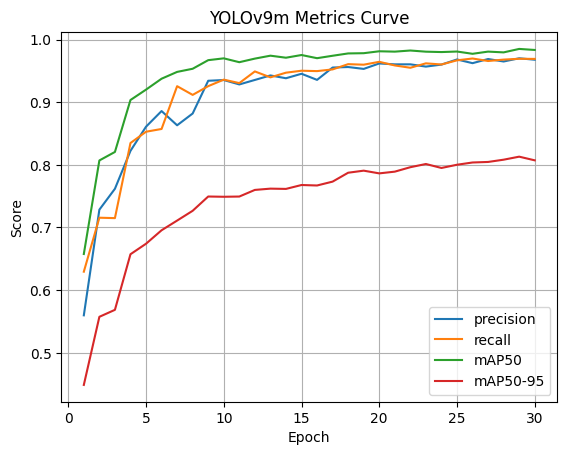

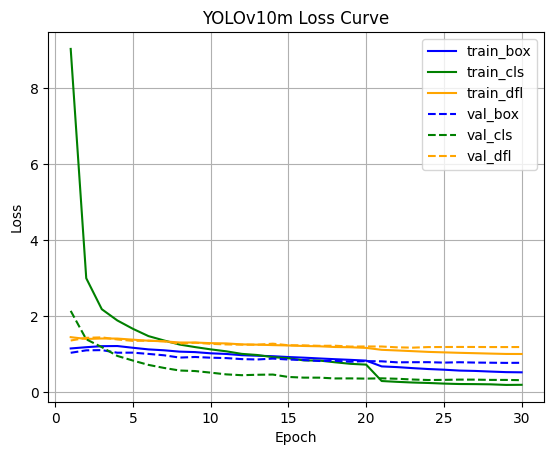

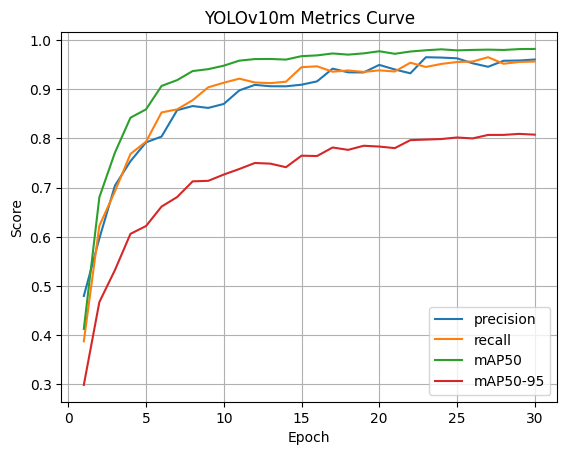

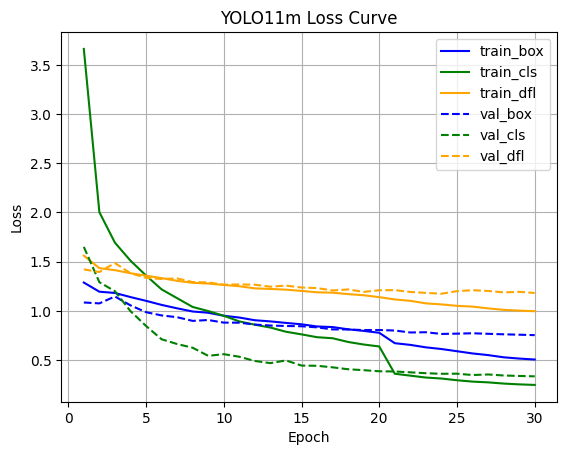

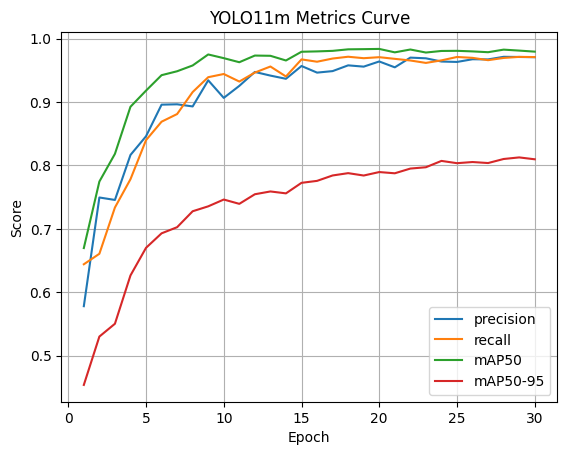

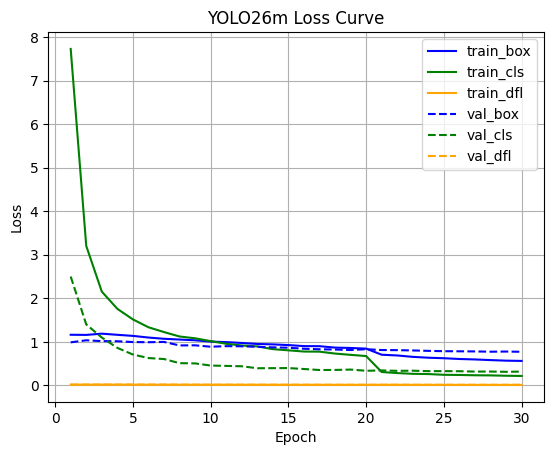

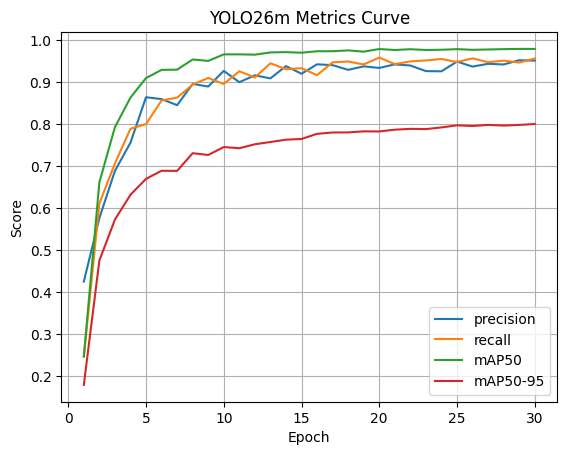

In [ ]:
# Plot naming and exact model directory name 
models = {
    "YOLOv8m": 'yolov8m',
    "YOLOv9m": 'yolov9m',
    "YOLOv10m": 'yolov10m',
    "YOLO11m": 'yolo11m',
    "YOLO26m": 'yolo26m',
}

for name, dirname in models.items():
    result = 'results.csv'
    result_path = os.path.join(TRAIN_RESULT_PATH, dirname, result)
    
    plot_training_curves(result_path, name)

### Plot Combined Model Curves

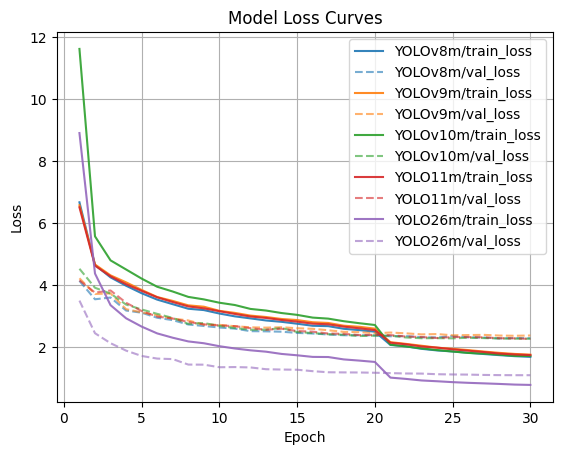

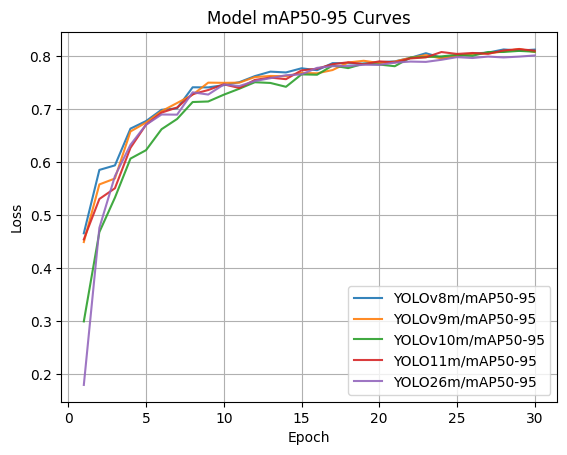

In [ ]:
names = list(models.keys())  # Model plot name
dirnames = models.values()
result_paths = [os.path.join(TRAIN_RESULT_PATH, p, result) for p in dirnames]

plot_training_comparison(result_paths, names)

## Test Set Predictions

In [ ]:
results_all = []

for name, dirname in models.items():

    print(f"Evaluating {name}")

    weight = 'weights/best.pt'
    weight_path = os.path.join(TRAIN_RESULT_PATH, dirname, weight)

    res = evaluate_model(
        model_path=weight_path,
        model_name=name,
        data_yaml=YAML_PATH,
    )

    res["model"] = name
    results_all.append(res)

Evaluating YOLOv8m
Ultralytics 8.3.213  Python-3.12.7 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce GTX 1050, 3072MiB)
Model summary (fused): 93 layers, 25,872,184 parameters, 0 gradients, 78.9 GFLOPs
val: Fast image access  (ping: 8.611.2 ms, read: 1.00.3 MB/s, size: 24.9 KB)
val: Scanning E:\Kuliah\Skripsi\Project\BISINDO-Vowels-Detection-YOLOv8\dataset_yolo\labels\test.cache... 717 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 717/717  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 0.9it/s 48.6s1.0ss
                   all        717        717       0.97      0.962      0.981      0.813
                     A         13         13      0.915      0.827      0.979      0.867
                     B         14         14          1      0.937      0.995      0.882
                     C         14         14      0.996          1      0.995      0.789
                     D         13         13      0.975       

## Plot All Model Confusion Matrixs

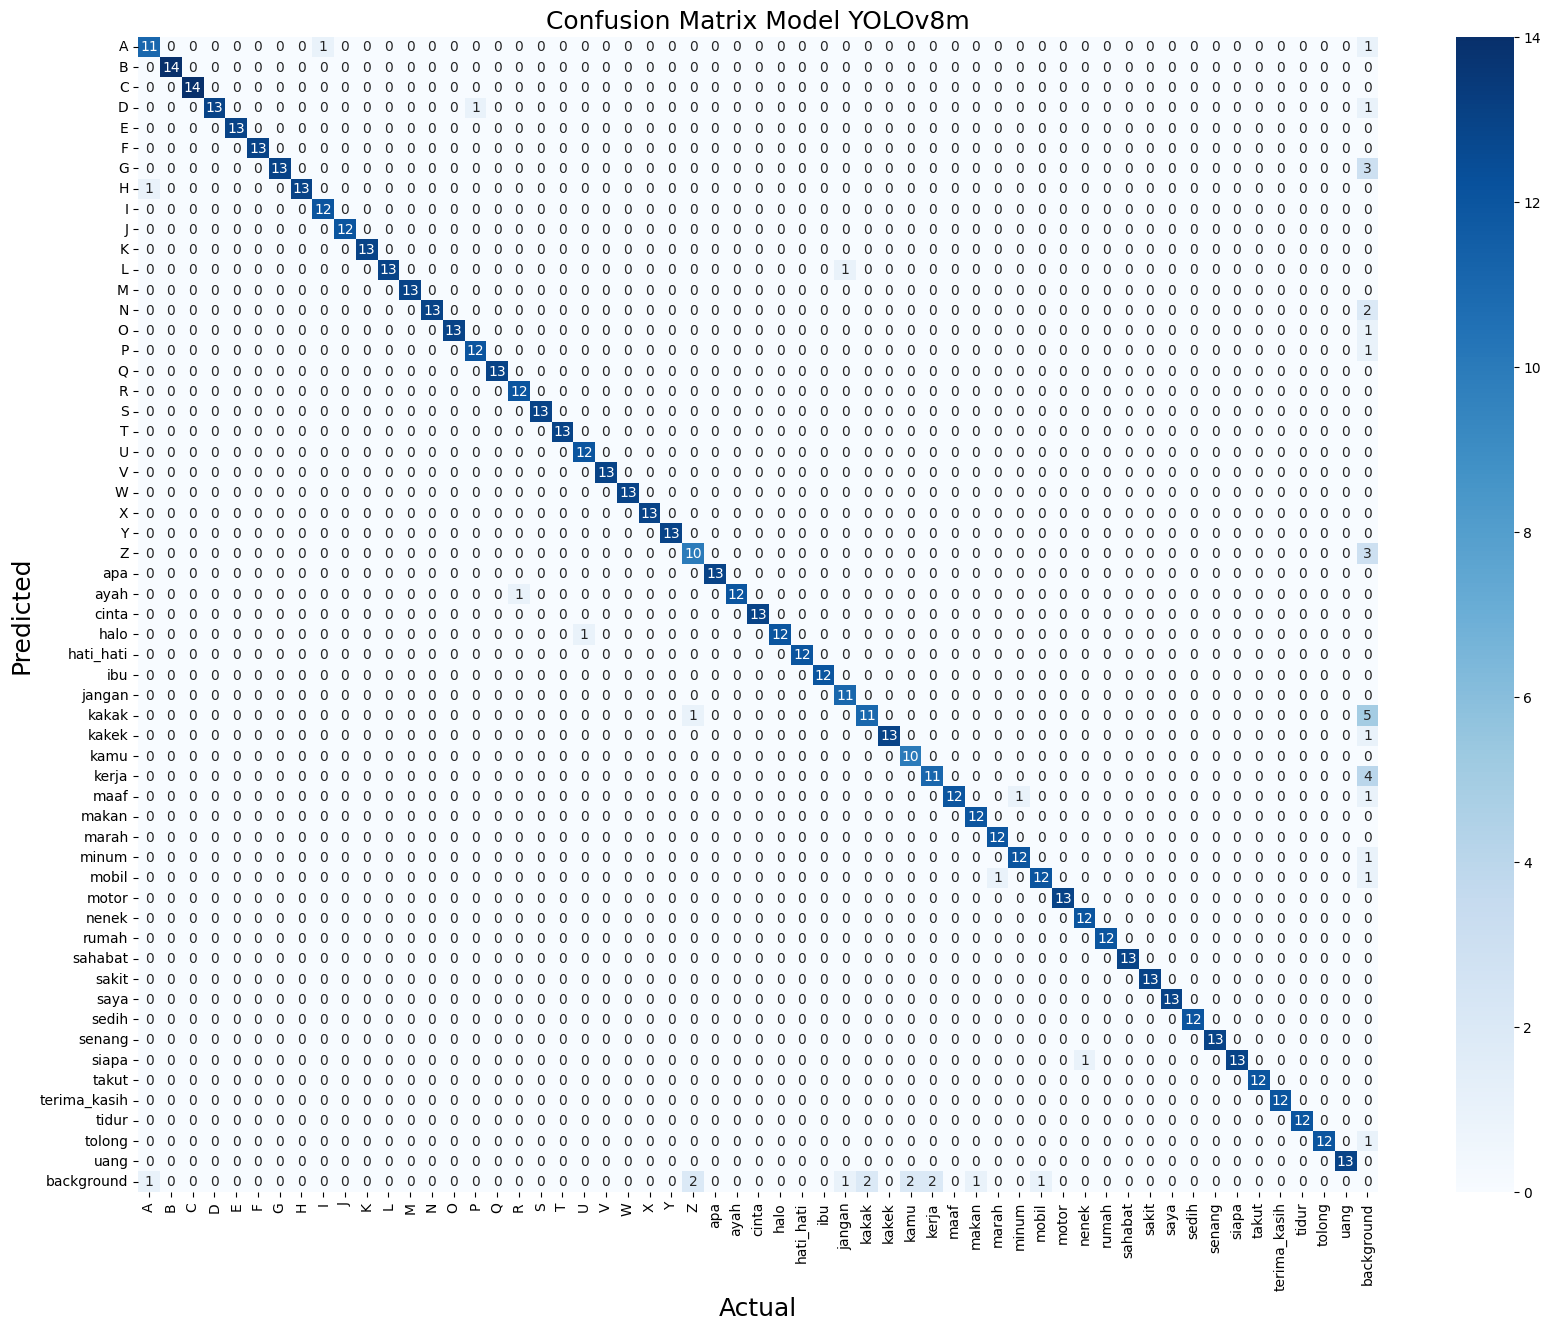

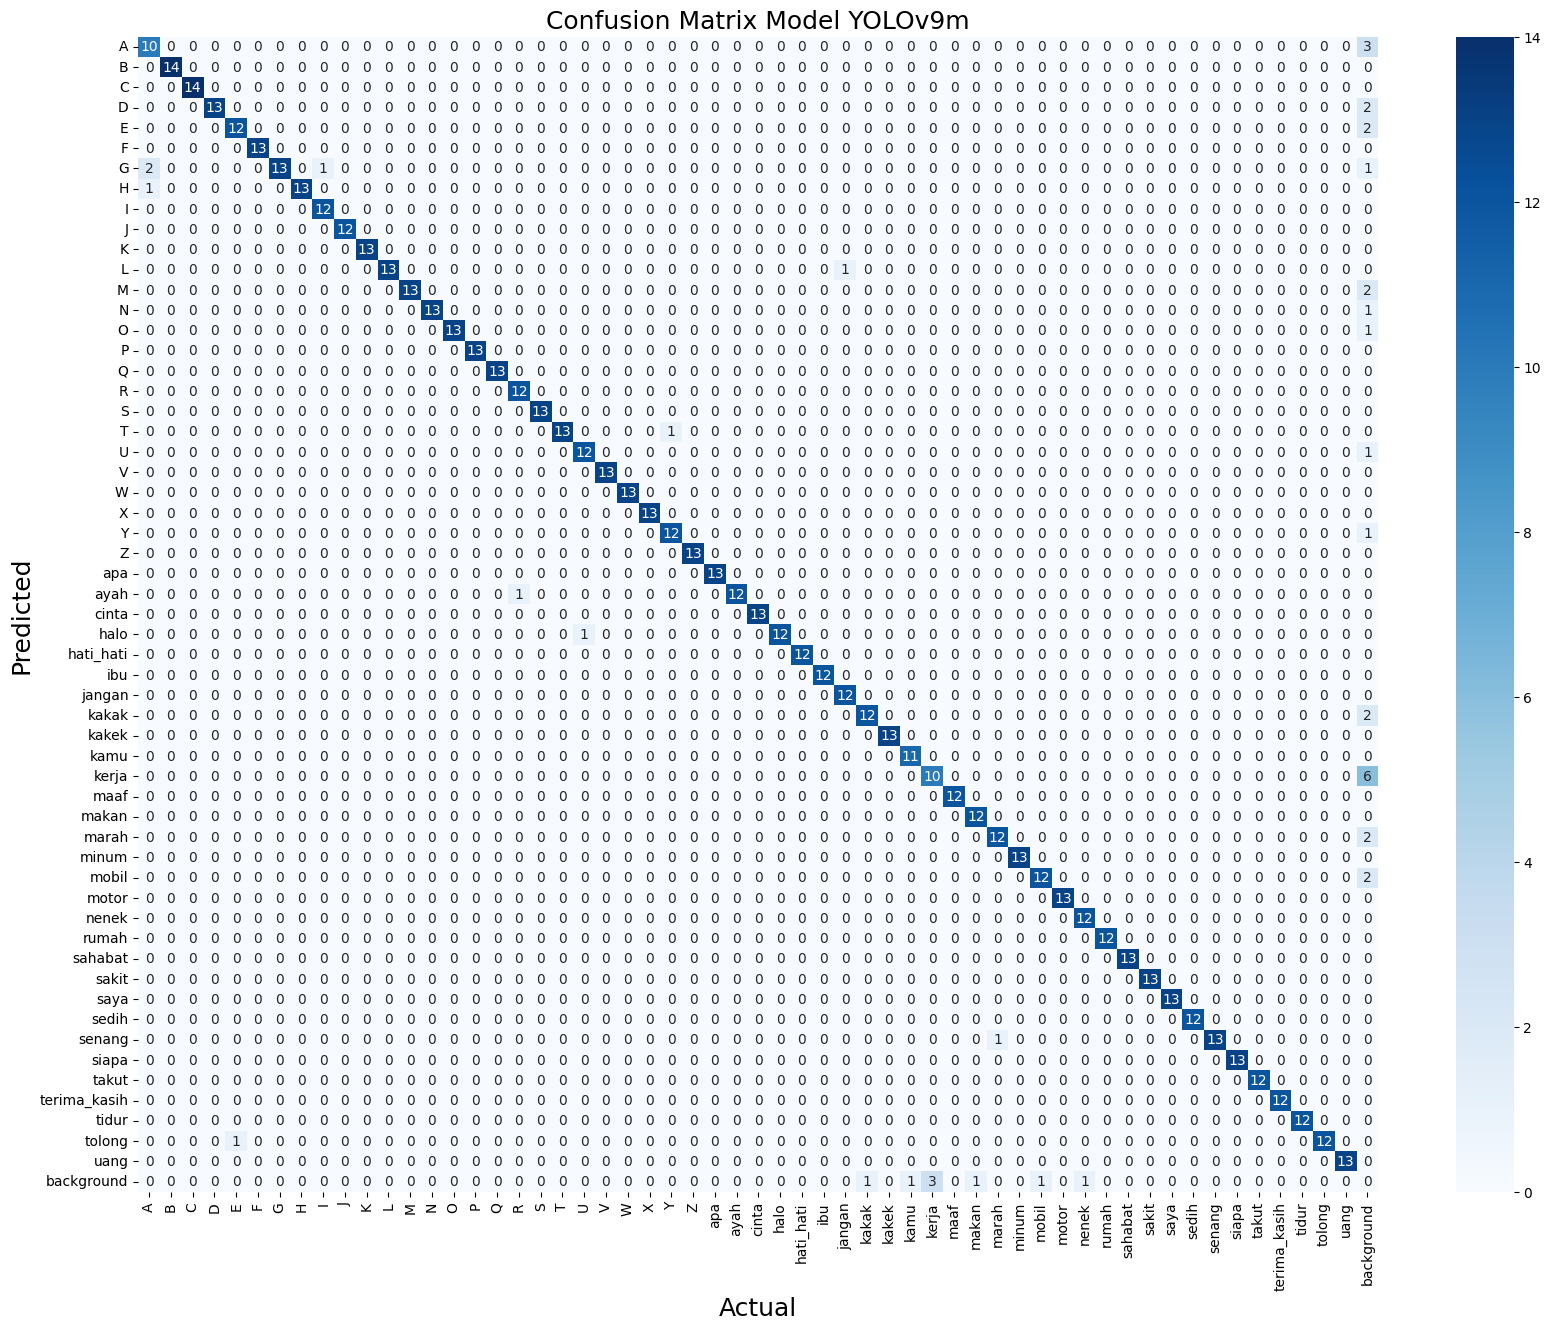

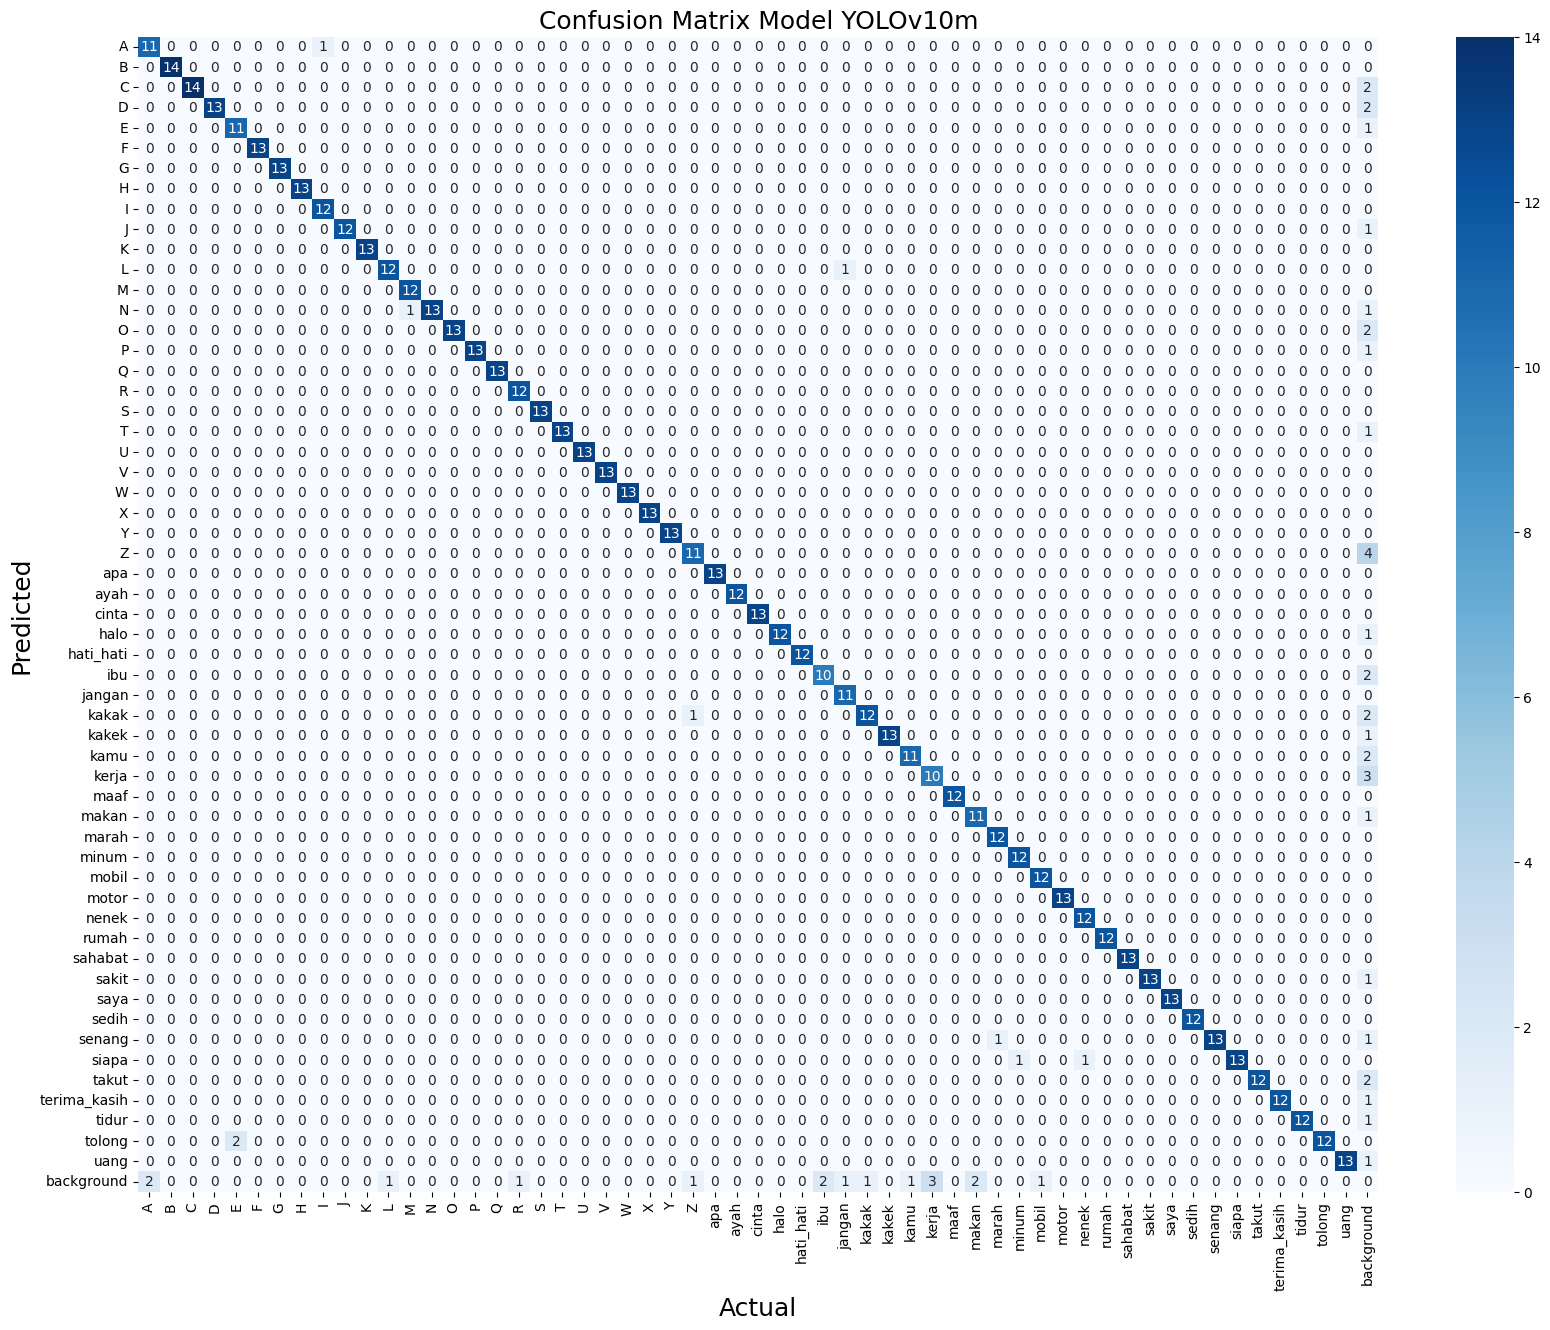

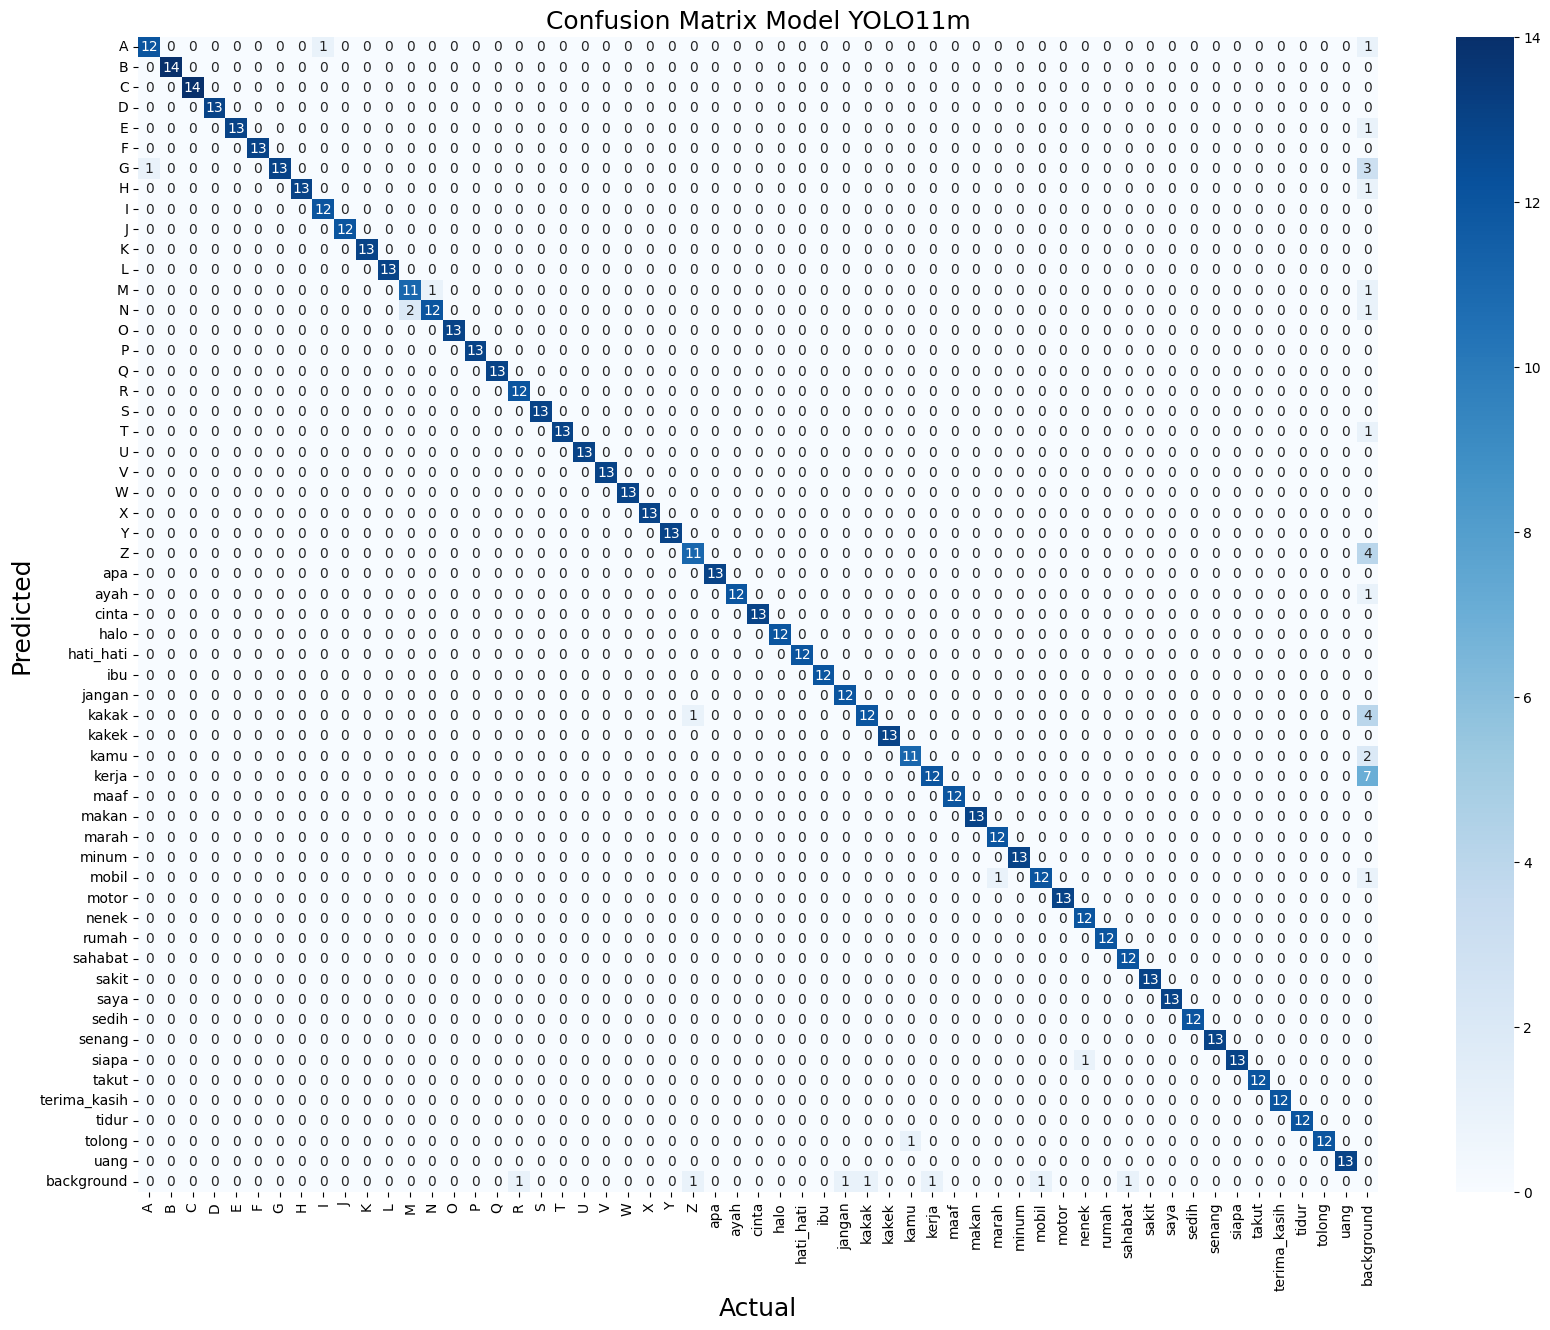

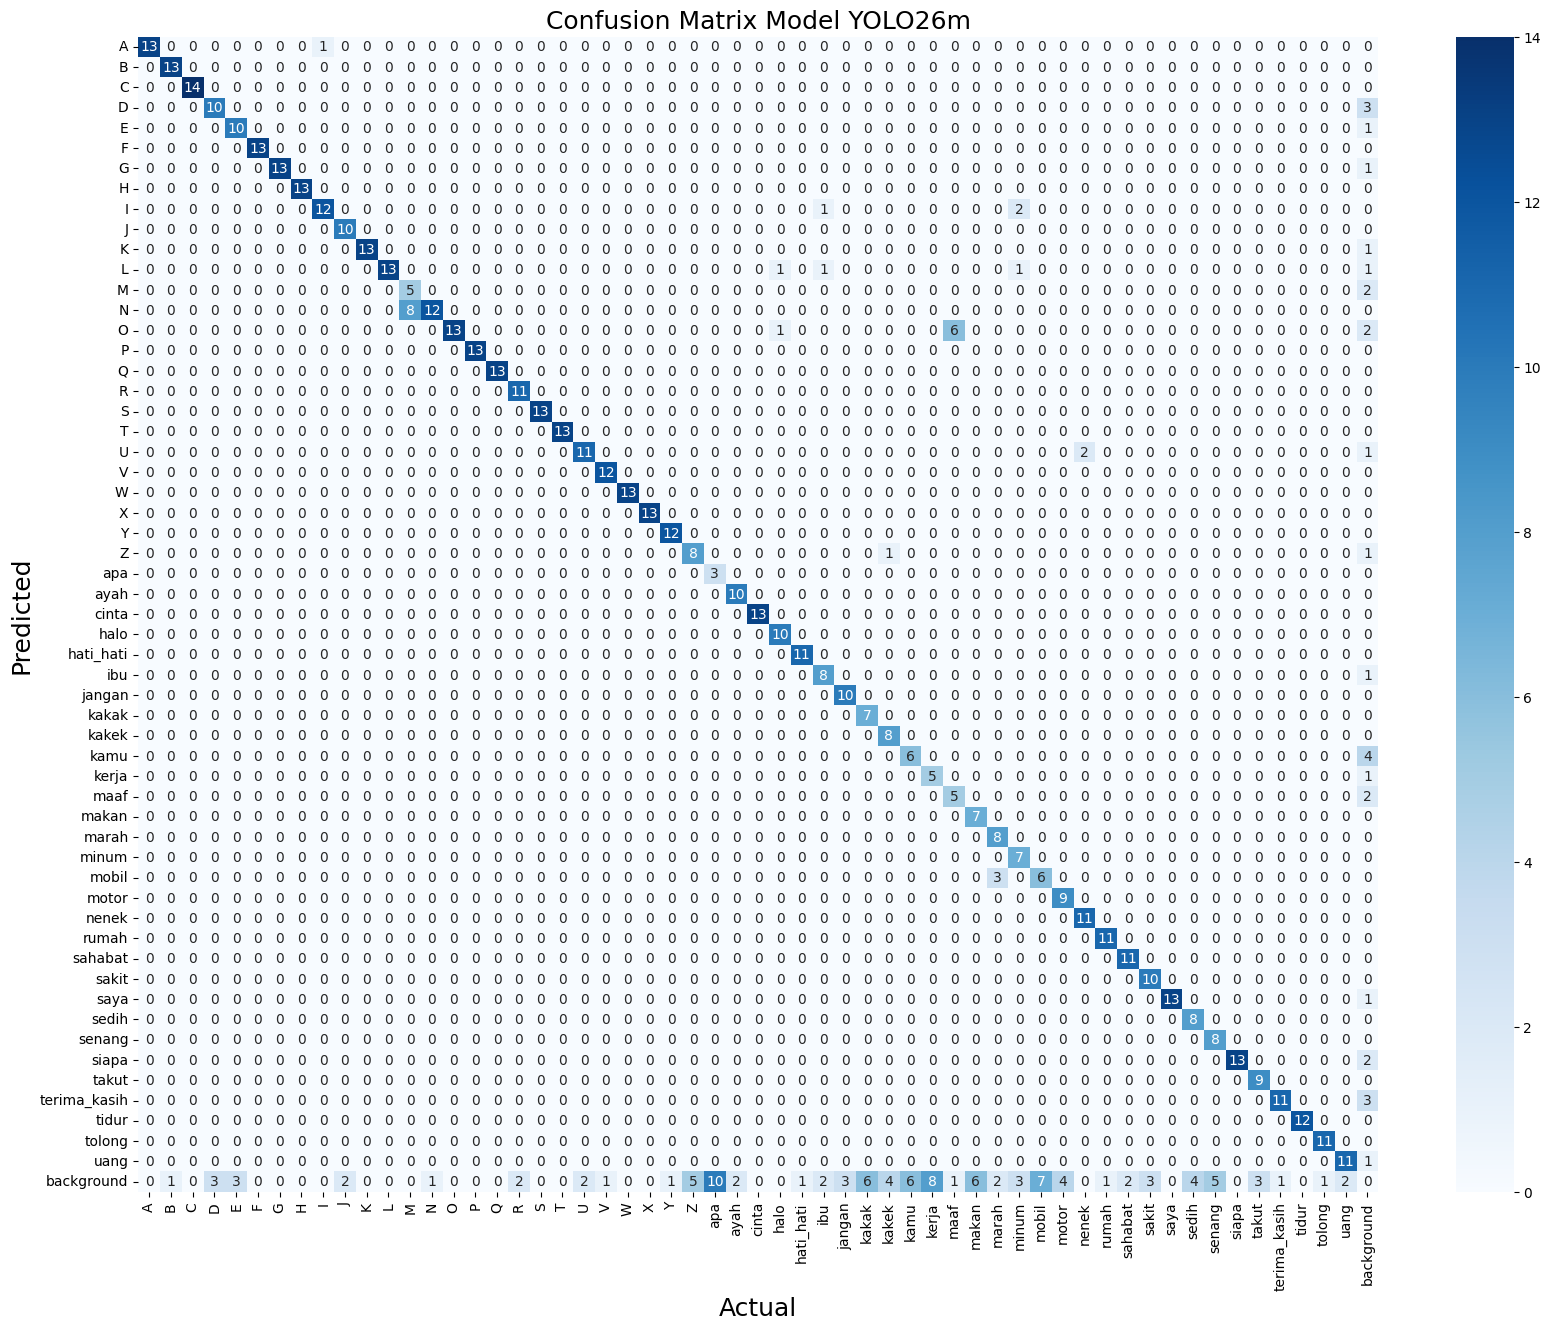

In [47]:
for model_results in results_all:
    model_name = model_results['model']
    confusion = model_results['confusion']
    
    plot_confusion_matrix(confusion, model_name)

## Combine All Model's Prediction Results

In [48]:
df_compare = pd.DataFrame(results_all)

df_table = df_compare[[
    'model', 'precision', 'recall', 'mAP50', 'mAP50-95', 'f1-score', 'latency'
]]

print(df_table)

      model  precision    recall     mAP50  mAP50-95  f1-score    latency
0   YOLOv8m   0.969732  0.961962  0.981211  0.812670  0.964947  53.906772
1   YOLOv9m   0.971913  0.967594  0.983453  0.819347  0.968858  65.647845
2  YOLOv10m   0.951382  0.955997  0.980377  0.811818  0.952423  55.219791
3   YOLO11m   0.960184  0.968630  0.983504  0.818713  0.963629  64.409919
4   YOLO26m   0.895866  0.855947  0.939105  0.721027  0.862341  65.256907


## Test Set Prediction Comparison

### Model Metrics Comparison

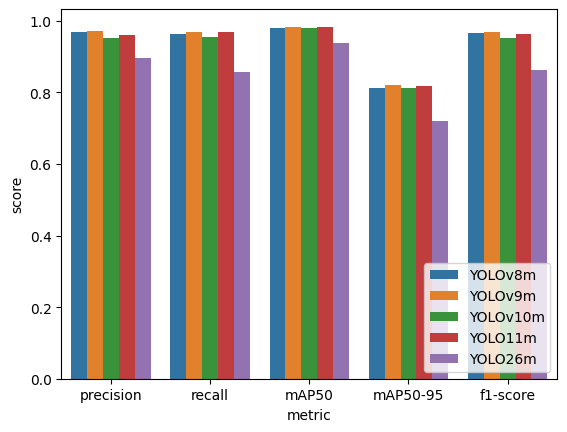

In [49]:
df_evaluation = df_table.drop(columns=['latency'])
df_eva_melt = df_evaluation.melt(
    id_vars='model', var_name='metric', value_name='score'
)

sns.barplot(df_eva_melt, x='metric', y='score', hue='model')
plt.legend(loc='lower right')

plt.show()

### Latency Comparison

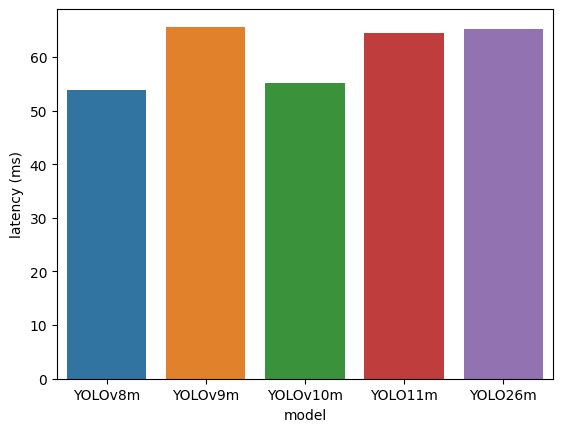

In [50]:
sns.barplot(df_table, x='model', y='latency', hue='model')
plt.ylabel('latency (ms)')
plt.show()

### mAP50-95 based on Latency Comparison

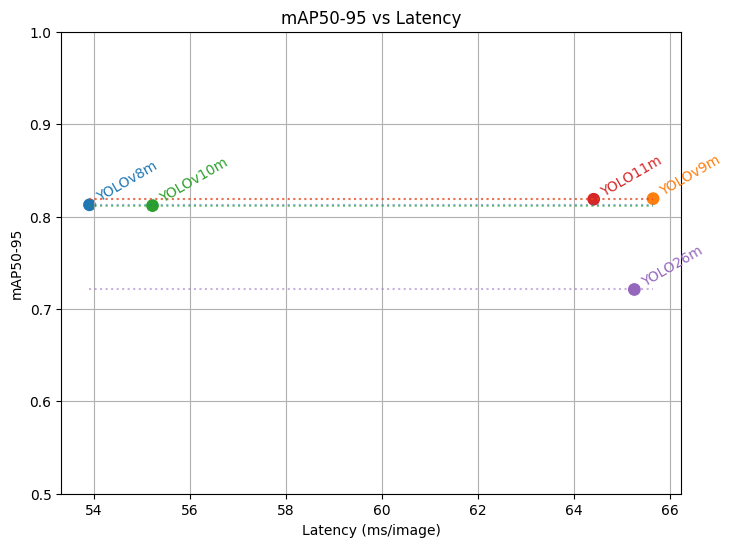

In [69]:
x = df_table['latency']
y = df_table['mAP50-95']
text = df_table['model']

plt.figure(figsize=(8, 6))

ax = sns.scatterplot(
    x=x,
    y=y,
    hue=text,
    s=100
)

leg = ax.legend()
lines = leg.get_lines()

for i in range(len(x)):
    c = lines[i].get_color()
    plt.text(x[i] + 0.1, y[i] + 0.004, f'{text[i]}', rotation=30, c=c)
    sns.lineplot(x=(min(x), max(x)), y=y[i], c=c, linestyle=':', alpha=0.5)

plt.ylim((0.5, 1))
# plt.xlim(left=0)
leg.remove()

plt.title("mAP50-95 vs Latency")
plt.xlabel("Latency (ms/image)")
plt.ylabel("mAP50-95")
plt.grid()
plt.show()